<a href="https://colab.research.google.com/github/herawati12/Projek_Semester5_Poptato/blob/irvan/Training_ResNet50_Kentang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ResNet50 — Klasifikasi Kondisi Visual Kentang (Good vs Bad)
**Dataset:** Hybrid Potato Tuber Dataset (`dataset_papas_hibrido.zip`) dari Google Drive. **Kelas:** `Buen estado = 0 = GOOD`, `Defectuoso = 1 = BAD`.

Notebook ini menggunakan **seluruh 36.000 gambar sebagai pengaturan awal**, pembagian train/val/test bawaan, pemeriksaan duplikasi identik antarsubset, dan **checkpoint + resume** ke Google Drive. Model utama ResNet50 disimpan terpisah dari MobileNetV2.

**Catatan metodologi:** hasil ini **tidak langsung setara** dengan eksperimen 4 arsitektur pada 1.000 gambar. Agar perbandingan antarmodel sah, gunakan dataset, split, dan protokol training yang sama. Kemiripan visual yang tidak identik/umbi sama belum otomatis terdeteksi oleh SHA-256.

## 1. Mount Drive dan konfigurasi
Aktifkan **Runtime → Change runtime type → GPU**. Sesuaikan hanya `PROJECT_DIR` jika folder Drive berbeda. Setelah koneksi terputus, jalankan kembali notebook mulai atas; folder checkpoint tidak perlu dihapus.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, csv, hashlib, zipfile, shutil, time, random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_recall_fscore_support

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
PROJECT_DIR = Path('/content/drive/MyDrive/datasets')
ZIP_PATH = PROJECT_DIR / 'dataset_papas_hibrido.zip'
OUT_DIR = PROJECT_DIR / 'hasil_resnet50_full'
OUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path('/content/potato_dataset_resnet50')  # lokal Colab agar pembacaan lebih cepat
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS_HEAD = 12
DO_FINE_TUNE = True
EPOCHS_FINE = 8
UNFREEZE_LAST_N = 30

CLASS_NAMES = ['Buen estado', 'Defectuoso']  # urutan eksplisit, alfabetis
DISPLAY_NAMES = ['GOOD', 'BAD']
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
assert ZIP_PATH.is_file(), f'ZIP tidak ditemukan: {ZIP_PATH}'
print('ZIP:', ZIP_PATH, 'MB:', round(ZIP_PATH.stat().st_size/1024**2, 1))
print('Output:', OUT_DIR)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
ZIP: /content/drive/MyDrive/datasets/dataset_papas_hibrido.zip MB: 182.9
Output: /content/drive/MyDrive/datasets/hasil_resnet50_full


## 2. Ekstraksi dataset dan validasi struktur
ZIP tidak perlu dipindah dari Drive; ekstraknya disimpan sementara di `/content/` agar training lebih cepat. Ekstraksi dilakukan ulang setelah reset runtime Colab, tetapi model tidak di-training ulang jika checkpoint/progres ada di Drive.

In [3]:
if not all((DATA_DIR / sub / CLASS_NAMES[0]).is_dir() and (DATA_DIR / sub / CLASS_NAMES[1]).is_dir() for sub in ['train','val','test']):
    print('Ekstrak ZIP ke disk lokal Colab...')
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        for member in z.infolist():
            target = (DATA_DIR / member.filename).resolve()
            if not target.is_relative_to(DATA_DIR.resolve()):
                raise ValueError(f'Nama file ZIP tidak aman: {member.filename}')
        z.extractall(DATA_DIR)

image_ext = {'.jpg','.jpeg','.png','.bmp','.webp'}
for split in ['train','val','test']:
    vals = {name: sum(p.suffix.lower() in image_ext for p in (DATA_DIR/split/name).iterdir()) for name in CLASS_NAMES}
    print(split, vals, 'total', sum(vals.values()))

Ekstrak ZIP ke disk lokal Colab...
train {'Buen estado': 11520, 'Defectuoso': 11520} total 23040
val {'Buen estado': 2880, 'Defectuoso': 2880} total 5760
test {'Buen estado': 3600, 'Defectuoso': 3600} total 7200


## 3. Hilangkan duplikasi **identik** lintas split
Prioritaskan train, kemudian validation, kemudian test. File yang memiliki hash SHA-256 sama persis dan sudah ada pada subset sebelumnya dikeluarkan dari daftar. Audit disimpan agar hasil dapat ditelusuri. **Keterbatasan:** foto yang mirip atau objek umbi yang sama dengan foto berbeda belum terdeteksi.

In [4]:
MANIFEST = OUT_DIR / 'manifest_clean.csv'
DUPLICATES = OUT_DIR / 'duplicates_exact.csv'

# Buat ulang dari salinan lokal ZIP agar manifest sesuai file pada run ini
seen = {}
manifest_rows, duplicate_rows = [], []
for split in ['train','val','test']:
    for label_idx, class_name in enumerate(CLASS_NAMES):
        files_in_class = sorted(p for p in (DATA_DIR/split/class_name).iterdir() if p.suffix.lower() in image_ext)
        for path in files_in_class:
            sha = hashlib.sha256(path.read_bytes()).hexdigest()
            rel = path.relative_to(DATA_DIR).as_posix()
            if sha in seen:
                duplicate_rows.append({'path':rel, 'identical_to':seen[sha], 'sha256':sha})
                continue
            seen[sha] = rel
            manifest_rows.append({'split':split, 'path':rel, 'label':label_idx, 'sha256':sha})

with MANIFEST.open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=['split','path','label','sha256']);w.writeheader();w.writerows(manifest_rows)
with DUPLICATES.open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=['path','identical_to','sha256']);w.writeheader();w.writerows(duplicate_rows)

for split in ['train','val','test']:
    subset = [r for r in manifest_rows if r['split']==split]
    print(split, 'GOOD:',sum(r['label']==0 for r in subset),'BAD:',sum(r['label']==1 for r in subset),'total:',len(subset))
print('Duplikat identik yang dikeluarkan:',len(duplicate_rows))
print('Audit:', DUPLICATES)

train GOOD: 11520 BAD: 11515 total: 23035
val GOOD: 2880 BAD: 2877 total: 5757
test GOOD: 3600 BAD: 3595 total: 7195
Duplikat identik yang dikeluarkan: 13
Audit: /content/drive/MyDrive/datasets/hasil_resnet50_full/duplicates_exact.csv


## 4. Pipeline citra untuk ResNet50
Gunakan **`tf.keras.applications.resnet50.preprocess_input`**. Ini berbeda dari MobileNetV2. Augmentasi hanya untuk training. Karena preprocessing berada **di pipeline dataset**, saat upload gambar nanti juga harus menerapkan preprocessing yang sama. Tidak perlu mengubah label secara manual.

In [5]:
AUTOTUNE = tf.data.AUTOTUNE
split_rows = {s:[r for r in manifest_rows if r['split']==s] for s in ['train','val','test']}

def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)  # masih 0..255
    return img, tf.cast(label, tf.float32)

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.12),
    tf.keras.layers.RandomZoom(0.12),
    tf.keras.layers.RandomContrast(0.12),
], name='augment_train')

def make_ds(split, training=False):
    rows = split_rows[split]
    paths = [str(DATA_DIR/r['path']) for r in rows]
    labels = [int(r['label']) for r in rows]
    ds = tf.data.Dataset.from_tensor_slices((paths,labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x,y:(augment(x,training=True),y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x,y:(tf.keras.applications.resnet50.preprocess_input(x),y),num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds('train',True)
val_ds = make_ds('val')
test_ds = make_ds('test')
print('Batch train:',len(train_ds),'val:',len(val_ds),'test:',len(test_ds))
print('Contoh shape:',next(iter(train_ds))[0].shape)

Batch train: 1440 val: 360 test: 450
Contoh shape: (16, 224, 224, 3)


## 5. Arsitektur ResNet50 dengan transfer learning
ResNet50 pretrained ImageNet tanpa dense top. Fase 1 melatih head; fase 2 membuka sejumlah layer terakhir untuk fine-tuning. Model menerima tensor **yang sudah dipreprocess dengan `resnet50.preprocess_input`**.

In [6]:
def build_model():
    backbone = tf.keras.applications.ResNet50(
        include_top=False, weights='imagenet', input_shape=(*IMG_SIZE,3))
    backbone.trainable = False
    inp = tf.keras.Input(shape=(*IMG_SIZE,3),name='resnet_preprocessed_image')
    z = backbone(inp, training=False)
    z = tf.keras.layers.GlobalAveragePooling2D()(z)
    z = tf.keras.layers.Dropout(0.30)(z)
    out = tf.keras.layers.Dense(1,activation='sigmoid',name='probability_bad')(z)
    m = tf.keras.Model(inp,out,name='ResNet50_Potato_GoodBad')
    return m,backbone

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                       tf.keras.metrics.Precision(name='precision_bad'),
                       tf.keras.metrics.Recall(name='recall_bad')])

BEST_HEAD=OUT_DIR/'best_head.keras'
BEST_FINE=OUT_DIR/'best_finetuned.keras'
FINAL_MODEL=OUT_DIR/'resnet50_best.keras'
PHASE1_DONE=OUT_DIR/'phase1_complete.json'
PHASE2_DONE=OUT_DIR/'phase2_complete.json'
print('Kelas sigmoid 1 = BAD; 0 = GOOD')

Kelas sigmoid 1 = BAD; 0 = GOOD


## 6. Training dengan checkpoint persisten di Google Drive
`BackupAndRestore` menyimpan state training setelah epoch agar `fit` dapat melanjutkan jika runtime terputus. `ModelCheckpoint` menyimpan model terbaik untuk validasi. Marker selesai mencegah pengulangan fase yang sudah selesai. Jika terputus di tengah epoch, epoch tersebut mungkin diulang. Jangan mengganti konfigurasi arsitektur/optimizer saat meneruskan backup yang sama.

In [7]:
def training_callbacks(phase, best_path):
    backup = OUT_DIR / f'backup_{phase}'
    return [
        tf.keras.callbacks.BackupAndRestore(backup_dir=str(backup), save_freq='epoch', delete_checkpoint=False),
        tf.keras.callbacks.ModelCheckpoint(str(best_path), monitor='val_loss', mode='min',
                                           save_best_only=True, verbose=1),
        tf.keras.callbacks.CSVLogger(str(OUT_DIR/f'history_{phase}.csv'),append=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),
    ]

if not PHASE1_DONE.exists():
    model, backbone=build_model()
    compile_model(model,1e-4)
    print('Fase 1: training head...')
    h1=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_HEAD,
                 callbacks=training_callbacks('head', BEST_HEAD))
    PHASE1_DONE.write_text(json.dumps({'completed':True,'time':time.ctime()}))
else:
    print('Fase 1 sudah selesai di Drive; tidak training ulang.')

assert BEST_HEAD.exists(), 'Model fase 1 belum tersedia; cek folder checkpoint.'
print('Best head:',BEST_HEAD)

Fase 1 sudah selesai di Drive; tidak training ulang.
Best head: /content/drive/MyDrive/datasets/hasil_resnet50_full/best_head.keras


## 7. Fine-tuning lapisan akhir ResNet50 (opsional)
Jika `DO_FINE_TUNE=True`, buka 30 layer terakhir dari backbone; BatchNormalization tetap dibekukan. Kecepatan lebih lambat tetapi berpotensi menaikkan akurasi. Punya checkpoint terpisah agar aman saat terputus.

In [8]:
if DO_FINE_TUNE:
    if not PHASE2_DONE.exists():
        model=tf.keras.models.load_model(BEST_HEAD)
        backbone=next(layer for layer in model.layers if isinstance(layer,tf.keras.Model) and 'resnet' in layer.name.lower())
        backbone.trainable=True
        for lay in backbone.layers[:-UNFREEZE_LAST_N]:
            lay.trainable=False
        for lay in backbone.layers:
            if isinstance(lay,tf.keras.layers.BatchNormalization):
                lay.trainable=False
        compile_model(model,1e-5)
        print('Fase 2: fine-tuning... trainable backbone layers:',sum(l.trainable for l in backbone.layers))
        h2=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_FINE,
                     callbacks=training_callbacks('fine', BEST_FINE))
        PHASE2_DONE.write_text(json.dumps({'completed':True,'time':time.ctime()}))
    else:
        print('Fase 2 sudah selesai di Drive; tidak training ulang.')

candidates=[p for p in [BEST_HEAD,BEST_FINE if DO_FINE_TUNE else BEST_HEAD] if p.exists()]
# Pilih model dari fase dengan validation loss terbaik, bukan otomatis fase fine-tune
scores=[]
for p in dict.fromkeys(candidates):
    m=tf.keras.models.load_model(p)
    res=m.evaluate(val_ds,verbose=0,return_dict=True)
    scores.append((res['loss'],str(p)))
    print(p.name, 'val_loss=',round(res['loss'],5),'val_accuracy=',round(res['accuracy'],5))
winning_path=Path(min(scores)[1])
if not FINAL_MODEL.exists() or winning_path.stat().st_mtime > FINAL_MODEL.stat().st_mtime:
    shutil.copy2(winning_path,FINAL_MODEL)
print('MODEL PILIHAN:',winning_path.name, '→',FINAL_MODEL)

Fase 2 sudah selesai di Drive; tidak training ulang.
best_head.keras val_loss= 0.04479 val_accuracy= 0.98524
best_finetuned.keras val_loss= 0.00295 val_accuracy= 0.99948
MODEL PILIHAN: best_finetuned.keras → /content/drive/MyDrive/datasets/hasil_resnet50_full/resnet50_best.keras


## 8. Evaluasi final test set (tidak untuk memilih hyperparameter)
Kesalahan paling penting untuk PBL: **Bad diprediksi Good** (lolos ke proses timbang). Test set bawaan dibersihkan dari duplikat yang identik dengan train/val, tetapi audit near-duplicate tetap perlu.

450/450 ━━━━━━━━━━━━━━━━━━━━ 42s 82ms/step - accuracy: 0.9994 - loss: 0.0046 - precision_bad: 0.9997 - recall_bad: 0.9992
Evaluasi test: {'accuracy': 0.9994440674781799, 'loss': 0.0046341875568032265, 'precision_bad': 0.9997217059135437, 'recall_bad': 0.9991655349731445}
450/450 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step
Confusion matrix [Good,Bad]:
 [[3599    1]
 [   3 3592]]
              precision    recall  f1-score   support

        GOOD     0.9992    0.9997    0.9994      3600
         BAD     0.9997    0.9992    0.9994      3595

    accuracy                         0.9994      7195
   macro avg     0.9994    0.9994    0.9994      7195
weighted avg     0.9994    0.9994    0.9994      7195



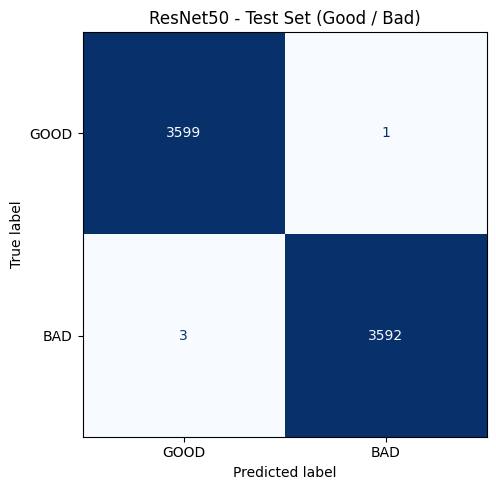

Laporan tersimpan: /content/drive/MyDrive/datasets/hasil_resnet50_full/hasil_test_resnet50.json


In [9]:
model=tf.keras.models.load_model(FINAL_MODEL)
metrics=model.evaluate(test_ds,verbose=1,return_dict=True)
print('Evaluasi test:',metrics)
y_true=np.array([int(r['label']) for r in split_rows['test']])
probs=model.predict(test_ds,verbose=1).reshape(-1)
y_pred=(probs>=0.5).astype(int)
assert len(y_true)==len(probs), 'Jumlah label dan prediksi tidak sama.'
cm=confusion_matrix(y_true,y_pred,labels=[0,1])
print('Confusion matrix [Good,Bad]:\n',cm)
print(classification_report(y_true,y_pred,target_names=DISPLAY_NAMES,digits=4,zero_division=0))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=DISPLAY_NAMES).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('ResNet50 - Test Set (Good / Bad)')
fig.tight_layout()
fig.savefig(OUT_DIR/'confusion_matrix_resnet50.png',dpi=160)
plt.show()

prec,rec,f1,_=precision_recall_fscore_support(y_true,y_pred,labels=[1],zero_division=0)
report={'model':'ResNet50','n_test':int(len(y_true)),'accuracy':float(accuracy_score(y_true,y_pred)),
        'precision_bad':float(prec[0]),'recall_bad':float(rec[0]),'f1_bad':float(f1[0]),
        'bad_pred_good':int(cm[1,0]),'good_pred_bad':int(cm[0,1]),'confusion_matrix':cm.tolist(),
        'model_file_mb':round(FINAL_MODEL.stat().st_size/1024**2,2)}
(OUT_DIR/'hasil_test_resnet50.json').write_text(json.dumps(report,indent=2))
print('Laporan tersimpan:',OUT_DIR/'hasil_test_resnet50.json')

## 9. Grafik riwayat training
Grafik fase 1 dan fase 2 ditampilkan secara terpisah agar perubahan proses training tidak disalahartikan.

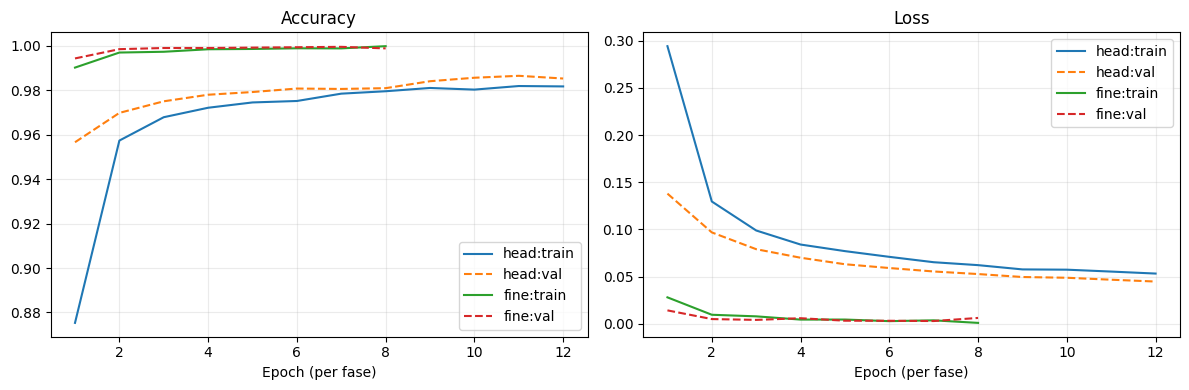

In [10]:
import pandas as pd
fig,axs=plt.subplots(1,2,figsize=(12,4))
for phase in ['head','fine']:
    f=OUT_DIR/f'history_{phase}.csv'
    if not f.exists(): continue
    d=pd.read_csv(f)
    if d.empty: continue
    axs[0].plot(range(1,len(d)+1),d['accuracy'],label=f'{phase}:train')
    axs[0].plot(range(1,len(d)+1),d['val_accuracy'],label=f'{phase}:val',linestyle='--')
    axs[1].plot(range(1,len(d)+1),d['loss'],label=f'{phase}:train')
    axs[1].plot(range(1,len(d)+1),d['val_loss'],label=f'{phase}:val',linestyle='--')
for a,title in zip(axs,['Accuracy','Loss']):
    a.set_title(title);a.set_xlabel('Epoch (per fase)');a.legend();a.grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT_DIR/'grafik_training_resnet50.png',dpi=160);plt.show()

## 10. Upload dan prediksi foto baru
Foto harus mewakili kondisi pemakaian nyata. **Tidak boleh melakukan preprocessing MobileNetV2** pada model ResNet50. Model menerima gambar yang sudah diproses oleh `resnet50.preprocess_input` seperti saat training.

In [ ]:
from google.colab import files
from PIL import Image, ImageOps
import io
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Memastikan model terdefinisi, jika tidak (misal setelah disconnect), muat dari Drive
try:
    model
    print("Model terdeteksi di memori, siap digunakan.")
except NameError:
    print("Model belum ada di memori. Memuat model terbaik dari Drive...")
    if 'FINAL_MODEL' in globals() and FINAL_MODEL.exists():
        model = tf.keras.models.load_model(FINAL_MODEL)
    else:
        # Jalur default jika variabel FINAL_MODEL belum didefinisikan
        default_model_path = Path('/content/drive/MyDrive/datasets/hasil_resnet50_full/resnet50_best.keras')
        if default_model_path.exists():
            model = tf.keras.models.load_model(default_model_path)
            print("Model berhasil dimuat dari:", default_model_path)
        else:
            raise FileNotFoundError("Model tidak ditemukan di Drive. Pastikan Anda sudah menjalankan sel konfigurasi di atas.")

uploaded = files.upload()
for name, raw in uploaded.items():
    im = ImageOps.exif_transpose(Image.open(io.BytesIO(raw))).convert('RGB')
    # RGB 0..255 -> ResNet50 preprocessing BGR + mean subtraction
    x = np.asarray(im.resize(IMG_SIZE), dtype=np.float32)[None, ...]
    x = tf.keras.applications.resnet50.preprocess_input(x.copy())
    prob_bad = float(model.predict(x, verbose=0)[0, 0])
    label = 'BAD' if prob_bad >= 0.5 else 'GOOD'
    confidence = prob_bad if label == 'BAD' else 1 - prob_bad
    plt.figure(figsize=(5, 5))
    plt.imshow(im)
    plt.axis('off')
    plt.title(f'{name}\n{label} | skor {confidence*100:.2f}% | P(Bad)={prob_bad:.4f}')
    plt.show()
    print(name, 'GOOD=', round(1-prob_bad, 5), 'BAD=', round(prob_bad, 5))

Model terdeteksi di memori, siap digunakan.
